# The BRACS data set: labels, official split and whole-slide images

**Goal.** Document the data before any modelling: what the label file contains, whether the official Training/Validation/Testing split can be used for comparison with other work, what the slides look like technically, and what a tile looks like at each pyramid level. The notebook also derives the class weights that correct the loss for class imbalance.

**Outline.**
1. **Setup**: library versions and imports.
2. **Parameters**: paths and settings.
3. **Labels and split**: class distribution, audit of the official split, composition of the slide labels, class imbalance and loss weighting.
4. **Slide properties**: pyramid levels, resolution, scanner and scan date.
5. **Visual inspection**: one slide per class, the same tissue at pyramid levels 1 to 4, and random tiles.
6. **Summary and export**: the main facts as a table, and the tidy tables used by the next notebooks.

**Inputs / outputs.** Inputs: `labels/BRACS.xlsx` (slide label, patient, official set, regions of interest) and the `.svs` slides in `DATA_DIR`. Outputs: `slides.csv` (one row per slide with label, patient, set and technical properties) and `class_weights.csv` (loss weights computed on the Training set), written to `OUTPUT_DIR`.

**Decision on the split.** The official split is used unchanged, so that results are comparable with published work on BRACS. Section 3 documents its properties and the caveats that follow from them.

**Reproducibility.** Library versions are printed in section 1.1. All paths and settings are collected in section 2. Random choices (permutation test, tile examples) use the seed given there.

## 1. Setup

### 1.1 Environment and library versions
Prints the Python and library versions used in this run, so results can be traced back to the software that produced them.

In [1]:
# STEP 1: Import general-purpose third-party libraries
import sys
import matplotlib
import numpy as np
import pandas as pd
import pyvips
import torch

# STEP 2: Print library versions for reproducibility
print('System Version:', sys.version)
print('Numpy version:', np.__version__)
print('Pandas version:', pd.__version__)
print('Matplotlib version:', matplotlib.__version__)
print('PyTorch version:', torch.__version__)
print('pyvips version:', pyvips.__version__)

System Version: 3.14.7 (main, Aug 10 2026, 07:46:56) [GCC 16.1.1 20260728]
Numpy version: 2.5.4
Pandas version: 3.1.1
Matplotlib version: 3.11.2
PyTorch version: 2.15.0+cu132
pyvips version: 3.2.0


### 1.2 Imports
Imports the project's own building blocks from `utils/`: the label reader, the overview and audit functions, the slide scanner, the class weighting and the slide plots.

In [2]:
# STEP 1: Standard-library imports
from pathlib import Path

# STEP 2: Import this project's own building blocks (labels, overview plots, slide scan, class weights, slide plots)
from utils.labels import BRACS_CLASSES
from utils.dataset_overview import (build_slide_table, validate_labels, plot_class_distribution, plot_split_audit,
                                    plot_roi_composition, plot_slide_properties, build_summary)
from utils.class_weights import plot_loss_weighting, weighted_cross_entropy
from utils.slide_stats import scan_slides
from utils.plot_pyramid import plot_pyramid_levels, plot_class_gallery, plot_tile_examples

## 2. Parameters
All paths and settings in one place. `DATA_DIR` holds the `.svs` slides, `LABELS_FILE` is the label spreadsheet of the data set, and `OUTPUT_DIR` receives the tables exported at the end.

In [3]:
# Major variables
DATA_DIR = Path('/mnt/Data/bracs/data')          # STEP 1: Directory of source WSIs (.svs)
LABELS_FILE = Path('labels/BRACS.xlsx')          # STEP 2: Spreadsheet with slide label, patient, set and RoIs
OUTPUT_DIR = Path('outputs/00_data_overview')    # STEP 3: Where the tidy tables are written
TILE_SIZE = 224                                  # STEP 4: Tile edge in pixels (as in 01_wsi_to_vectors.ipynb)
TILE_EXAMPLE_LEVEL = 3                           # STEP 5: Pyramid level of the random tile examples (1 = full resolution)
SEED = 0                                         # STEP 6: Seed of every random choice in this notebook

## 3. Labels and split

### 3.1 Load and validate the labels
Reads the label sheet into one table (slide, patient, class, official set, number of regions of interest) and checks it: the number of slides and patients, duplicates, unknown classes or sets, and agreement with the `.svs` files on disk.

**The seven classes.** BRACS annotates regions of interest (RoIs) on haematoxylin and eosin (H&E) stained breast tissue with seven diagnostic categories, which follow the spectrum from normal tissue to invasive cancer and are commonly grouped into benign, atypical and malignant lesions. They are listed here from benign to malignant, in the order used in all figures.

| Class | Name | Group | Definition |
|---|---|---|---|
| **N** | Normal | benign | Normal breast tissue: ducts and lobules lined by a regular, single or double layer of epithelial cells, without proliferation or atypia. |
| **PB** | Pathological benign | benign | Benign lesions that are not normal tissue but show no epithelial proliferation with atypia, for example cysts, columnar cell change without atypia, adenosis or fibroadenoma-like change. They are the most frequent class in the data set. |
| **UDH** | Usual ductal hyperplasia | benign | A benign increase in the number of epithelial cells inside ducts. The cells are a mixed population, form irregular, slit-like spaces and show no atypia. It carries only a slightly increased risk of later cancer. |
| **FEA** | Flat epithelial atypia | atypical | Replacement of the normal epithelium of the terminal duct-lobular units by one to a few layers of mildly atypical cells, with a flat growth pattern and no complex architecture. It is a low-grade, non-obligate precursor lesion. |
| **ADH** | Atypical ductal hyperplasia | atypical | A proliferation of uniform, monomorphic cells with architectural patterns resembling low-grade ductal carcinoma in situ, but limited in extent or incomplete. It is a risk marker and the borderline between benign and malignant, and the diagnosis with the highest inter-observer variability. |
| **DCIS** | Ductal carcinoma in situ | malignant | A malignant proliferation of epithelial cells confined to the ducts: the basement membrane is intact and there is no invasion of the surrounding stroma. It is graded as low, intermediate or high by nuclear atypia. |
| **IC** | Invasive carcinoma | malignant | Malignant epithelial cells that have broken through the basement membrane and invade the surrounding stroma. It includes the invasive ductal and the invasive lobular types. |

**A clinical reading of the scale.** The seven classes can be read as four tiers of increasing clinical significance:

| Tier | Classes | Reading |
|---|---|---|
| No finding | N | The tissue is normal. |
| Benign | PB, UDH | A lesion is present but it is not cancer, and it usually needs no further action. UDH carries a slightly higher risk of later cancer. |
| Atypical (high risk) | FEA, ADH | Not cancer, but cells show atypia and the lesion is a marker of increased risk. When found on a biopsy it is often followed up more closely or excised, because a cancer may lie next to it. |
| Malignant | DCIS, IC | Cancer. DCIS is non-invasive (confined to the ducts); IC has invaded the surrounding tissue. |

Two cautions apply when using this reading.
- **The label describes tissue, not the person.** A normal slide does not mean that the patient has no cancer: a patient can have slides of several classes (section 3.3), and a slide takes the label of its highest-grade region. "No finding" holds only for a slide in which every region is normal.
- **The boundaries differ in difficulty and importance.** The clinically decisive boundary is between non-cancer (N, PB, UDH, FEA, ADH) and cancer (DCIS, IC), which can be reported as a binary result next to the seven-class result. The hardest boundaries for the model and for pathologists are between neighbouring classes, above all ADH against DCIS, followed by UDH, FEA and ADH among themselves.

The classes form an ordered scale, and neighbouring classes (UDH, FEA and ADH in particular) differ by subtle, graded features. This is why confusion between adjacent classes is expected and also occurs between pathologists. The label of a **slide** is the highest-grade RoI it contains (the order above), so a slide labelled IC also contains benign and in situ regions (section 3.4). The definitions summarise the usual diagnostic criteria for orientation; the labels themselves are those assigned by the BRACS pathologists.

In [4]:
# STEP 1: Build the label table (technical slide properties are added in section 4)
table = build_slide_table(LABELS_FILE)

# STEP 2: Check it against itself and against the files on disk
checks = validate_labels(table, DATA_DIR)

slides                : 547
patients              : 189
duplicate slides      : 0
unknown class         : 0
unknown set           : 0
labelled but no file  : 0
file but no label     : 0


### 3.2 Class distribution
Number of slides per class, overall and within each official set. Whether the sets have the same class mix matters for comparing results: a classifier is trained on the Training mix and evaluated on a Testing mix that may differ.

set    Training  Validation  Testing  total
label                                      
N            27          10        7     44
PB          120          11       16    147
UDH          56           9        9     74
FEA          24           6       11     41
ADH          28           8       12     48
DCIS         40           9       12     61
IC          100          12       20    132

Share of each set (%):
set    Training  Validation  Testing
label                               
N           6.8        15.4      8.0
PB         30.4        16.9     18.4
UDH        14.2        13.8     10.3
FEA         6.1         9.2     12.6
ADH         7.1        12.3     13.8
DCIS       10.1        13.8     13.8
IC         25.3        18.5     23.0


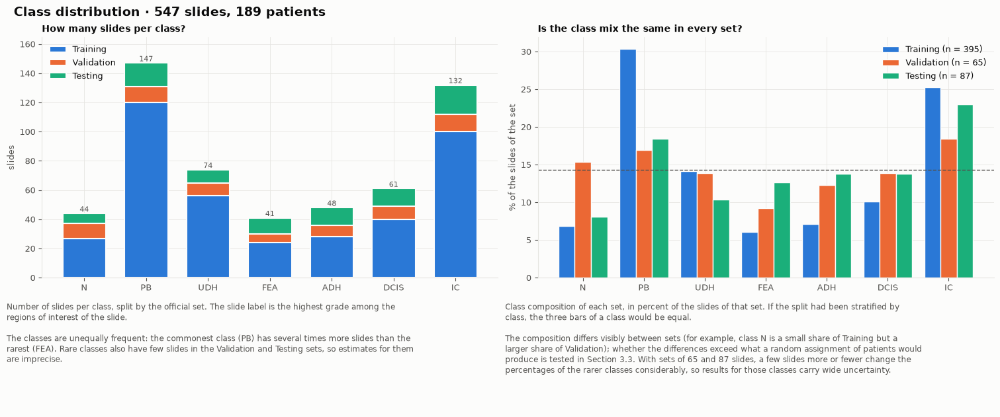

In [5]:
# STEP 1: Slides per class and set, and the class mix within each set
distribution = plot_class_distribution(table)

### 3.3 Audit of the official split
Checks the split on two levels. At class level, a permutation test (reassigning whole patients to sets) asks whether the class mix of the sets differs more than a random assignment of patients would produce, and Cramér's V measures the strength of the association. At patient level, it counts patients whose slides lie in several sets, patients whose slides have different labels, and slides per patient. Slides of one patient are not independent (same case, same staining batch), so a split must keep them together.

**Decision.** The official split is used unchanged for comparability. Departures found here are reported in the thesis and handled in the classification notebook (patient-grouped folds inside Training, balanced metrics, wide intervals for small classes).

Class x set : chi2 = 24.0, Cramer's V = 0.15, patient-level permutation p = 0.465 (5000 permutations)
Patients    : 189  |  with slides in several sets: 1 ['67']  |  with slides of several classes: 78
  patient 67: Training 3, Validation 2


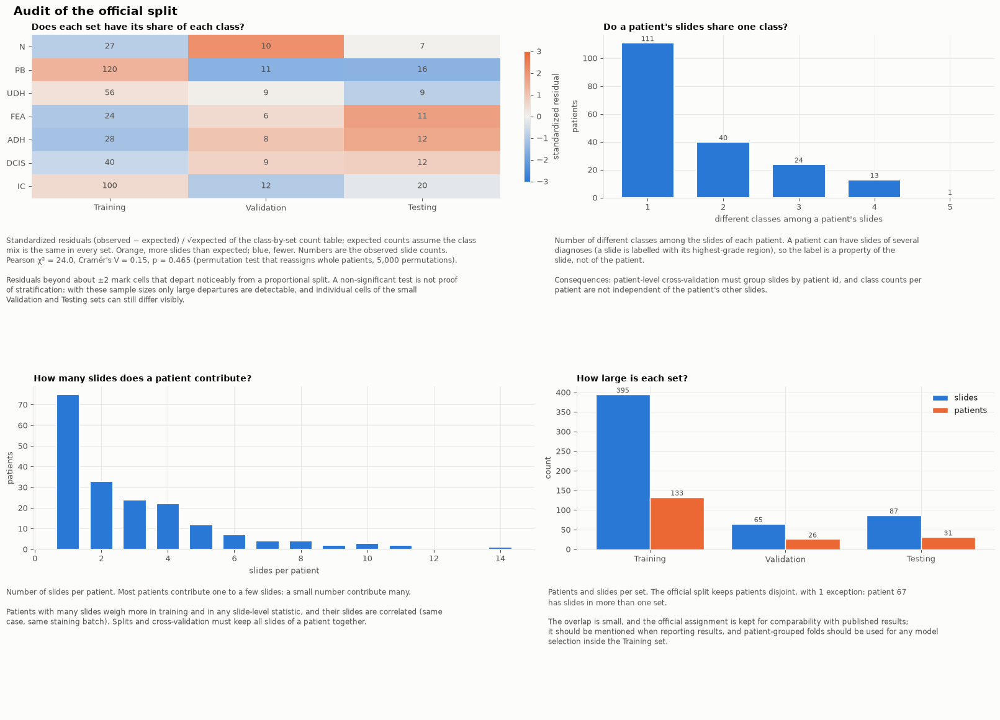

In [6]:
# STEP 1: Class-by-set test, patient overlap, slides per patient
audit = plot_split_audit(table, n_perm=5000, seed=SEED)

### 3.4 Composition of the slide labels
A slide label is the highest grade among its regions of interest (RoIs), so a slide labelled IC also contains benign and in situ regions. This section quantifies that mixture from the RoI sheet. It sets an upper limit on what tile-level labels can mean: if every tile inherits the slide label, a share of tiles is labelled with a class that does not describe them.

387 of 547 slides have an RoI breakdown; RoIs per slide: median 6, range 1 to 119
Mean RoI share (%) by slide class (rows) and RoI class (columns):
          N    PB   UDH   FEA   ADH  DCIS    IC
N     100.0   0.0   0.0   0.0   0.0   0.0   0.0
PB     22.1  77.7   0.0   0.2   0.0   0.0   0.0
UDH     9.7  30.8  59.5   0.0   0.0   0.0   0.0
FEA    12.4  32.5   9.9  45.2   0.0   0.0   0.0
ADH     5.1   8.7  25.0  23.0  38.3   0.0   0.0
DCIS    5.9   9.2   8.7  12.6  16.6  47.0   0.0
IC      5.4   3.1   3.0   7.4   7.6  12.3  61.2


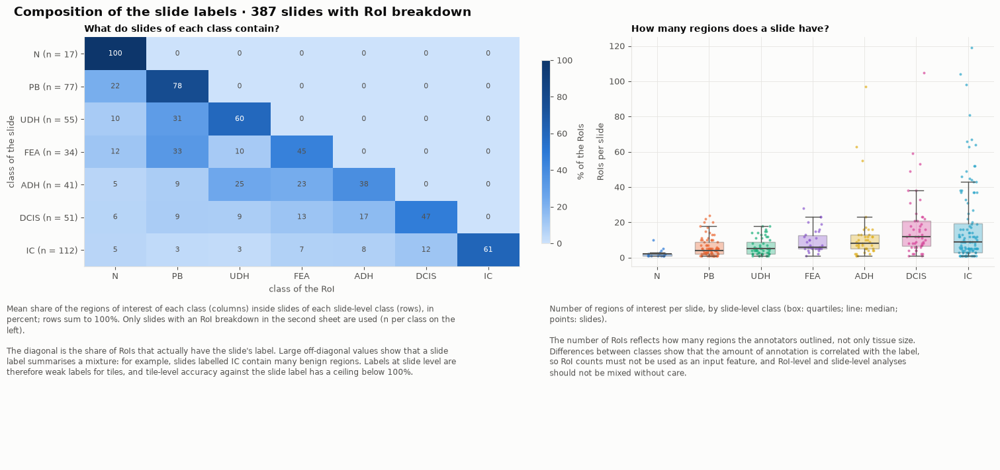

In [7]:
# STEP 1: Share of each RoI class inside slides of each slide-level class, and RoIs per slide
composition = plot_roi_composition(table, LABELS_FILE)

### 3.5 Class imbalance and loss weighting
The classes are unequally frequent, so an unweighted loss is dominated by the frequent classes and a model can lower it by reproducing the class frequencies. Class weights rescale each class's contribution. They are computed on the **Training set only**, because Validation and Testing must stay untouched by the training procedure. Three rules are compared: inverse frequency (every class contributes equally), its square root (milder) and the class-balanced weights of Cui et al. (2019). The figure shows the weights, the share of the loss that each class contributes, and what the loss rewards for three fixed reference predictors.

The weights change the training objective only. Evaluation uses unweighted balanced accuracy and per-class recall on the unchanged Validation and Testing sets.

Samples 395  |  classes 7  |  imbalance ratio (largest / smallest class) 5.0
 class      n    inverse       sqrt  effective
     N     27      2.090      1.516      2.059
    PB    120      0.470      0.719      0.485
   UDH     56      1.008      1.053      1.007
   FEA     24      2.351      1.608      2.313
   ADH     28      2.015      1.489      1.987
  DCIS     40      1.411      1.245      1.399
    IC    100      0.564      0.788      0.576


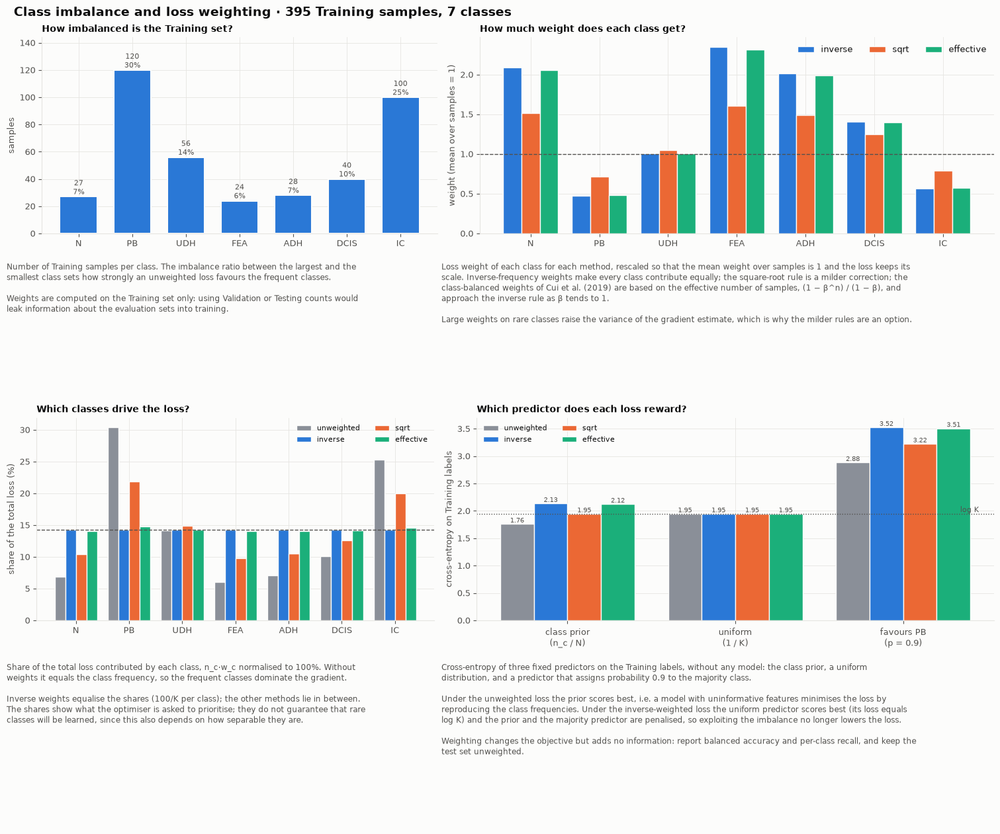

In [8]:
# STEP 1: Integer class labels of the Training slides (slide level; pass tile labels instead for tile-level training)
y_train = table.loc[table['set'] == 'Training', 'label'].cat.codes.to_numpy()

# STEP 2: Weights per method and the effect on the loss
weighting = plot_loss_weighting(y_train, BRACS_CLASSES)

# STEP 3: The loss to use in the classifier, here with the inverse-frequency weights
loss_fn = weighted_cross_entropy(weighting['weights']['inverse'])

## 4. Slide properties

### 4.1 Scan of the slide headers
Reads the header of every slide (no pixels are decoded): the number of pyramid levels, the size of each level and its downsample factor, the file size, and the scanner, magnification, resolution (microns per pixel, MPP), scan date and JPEG quality stored by the scanner. Level 1 is the full resolution; higher levels are more downsampled. The table is merged with the labels.

In [9]:
# STEP 1: Read the headers of the slides in the label table
scan = scan_slides(DATA_DIR, slides=table['slide'].tolist())

# STEP 2: Merge them with the labels (one row per slide)
table = build_slide_table(LABELS_FILE, scan)
table[['slide', 'label', 'set', 'n_levels', 'gigapixels', 'mpp', 'scan_date']].head()

Scanning slides:   0%|          | 0/547 [00:00<?, ?it/s]

,slide,label,set,n_levels,gigapixels,mpp,scan_date
0,BRACS_264,PB,Testing,4,6.411420,0.2524,2021-02-26
1,BRACS_265,UDH,Validation,4,6.442270,0.2524,2021-02-26
2,BRACS_280,IC,Training,4,7.070368,0.2524,2021-02-26
3,BRACS_281,IC,Training,4,7.766184,0.2524,2021-02-26
4,BRACS_283,IC,Training,4,5.451053,0.2524,2021-02-26


### 4.2 Technical properties and batch screen
Summarises slide size, the pyramid levels, resolution, scan year and the number of tiles each level would give. Properties that differ between classes or sets are potential confounders: a classifier can learn them instead of the pathology. The scan year and the class are compared with Cramér's V as a first screen; the slide effect in the embeddings themselves is analysed in `01_wsi_to_vectors.ipynb`.

Scanner(s)       : {'SS7212': 547}
Magnification    : {40.0: 547}   JPEG quality: {70: 547}
MPP (um/pixel)   : {0.2519: 481, 0.2524: 66}
Scan years       : {2019: 228, 2020: 253, 2021: 66}   (class x year Cramer's V = 0.27)
Pyramid levels   : {3: 12, 4: 535}   |   downsample at level 4: {32.0: 406, 64.0: 129}
Full resolution  : median 8.0 gigapixels, max 16.0   |   file size median 1.85 GB, total 1057 GB


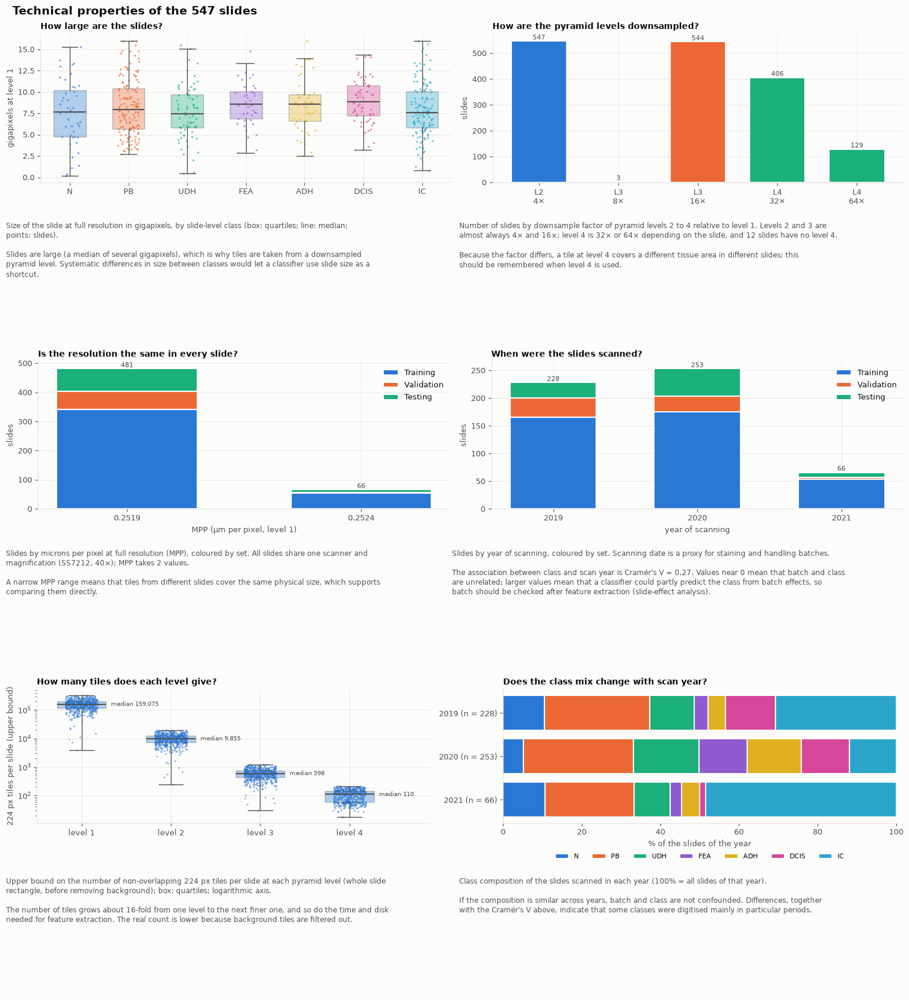

In [10]:
# STEP 1: Size, levels, resolution, scan year, tiles per level, class mix per year
properties = plot_slide_properties(table, tile_size=TILE_SIZE)

## 5. Visual inspection of the slides

### 5.1 One slide per class
One overview image per class. The slide of median full-resolution size within each class is shown, so that the choice is deterministic and not made by appearance. The images illustrate the variation in tissue amount, staining and artefacts; they are not evidence of class differences.

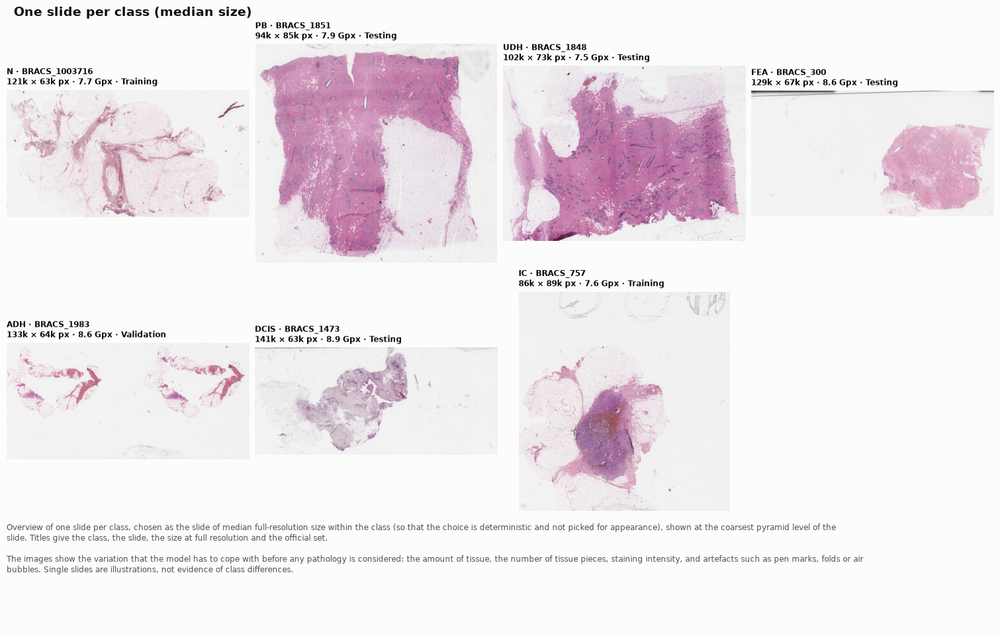

In [11]:
# STEP 1: Overview of the median-size slide of every class at its coarsest pyramid level
gallery = plot_class_gallery(table)

### 5.2 The same tissue at pyramid levels 1 to 4
Shows how the pyramid level changes what the model sees. For a chosen slide, a window with plenty of tissue is displayed at levels 1 to 4 (top row; the square marks one 224 px tile), together with the tile the model would receive at each level (bottom row, native pixels). A coarser level covers a larger tissue area per tile at lower resolution: tissue architecture instead of cellular detail. Slides without level 4 are marked. Two slides are shown, one of the benign end and one of the invasive end of the label scale.

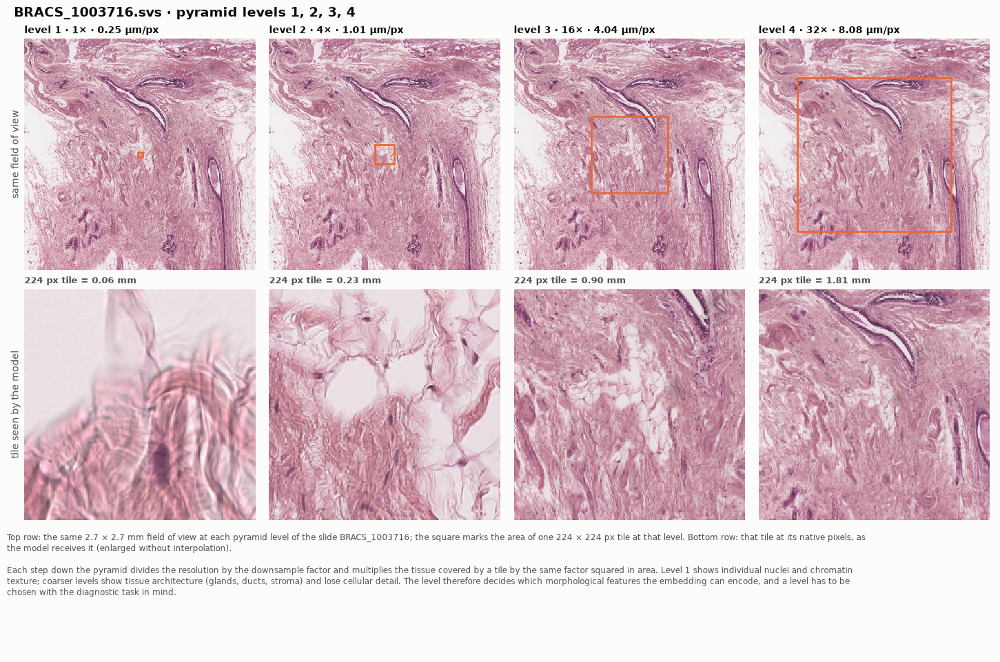

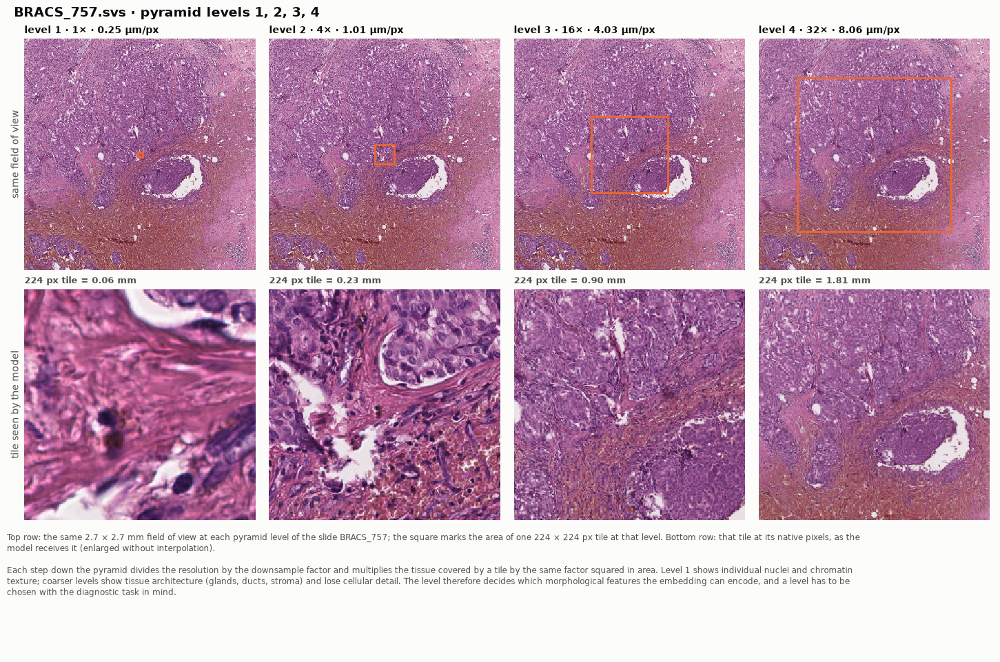

In [12]:
# STEP 1: The slides shown in 5.1 for the first and the last class, each at levels 1 to 4
shown = gallery['slides'].set_index('label')
for label in (BRACS_CLASSES[0], BRACS_CLASSES[-1]):
    pyramid = plot_pyramid_levels(shown.loc[label, 'path'], tile_size=TILE_SIZE)

### 5.3 Random tiles per class
Random tissue tiles of every class, each from a different slide, drawn at the pyramid level used for feature extraction and filtered with the same tissue filter as the pipeline. They are the inputs of the model before normalisation. The tiles of one slide label vary widely, because most slides also contain benign tissue, and differences in staining and sharpness between slides are visible.

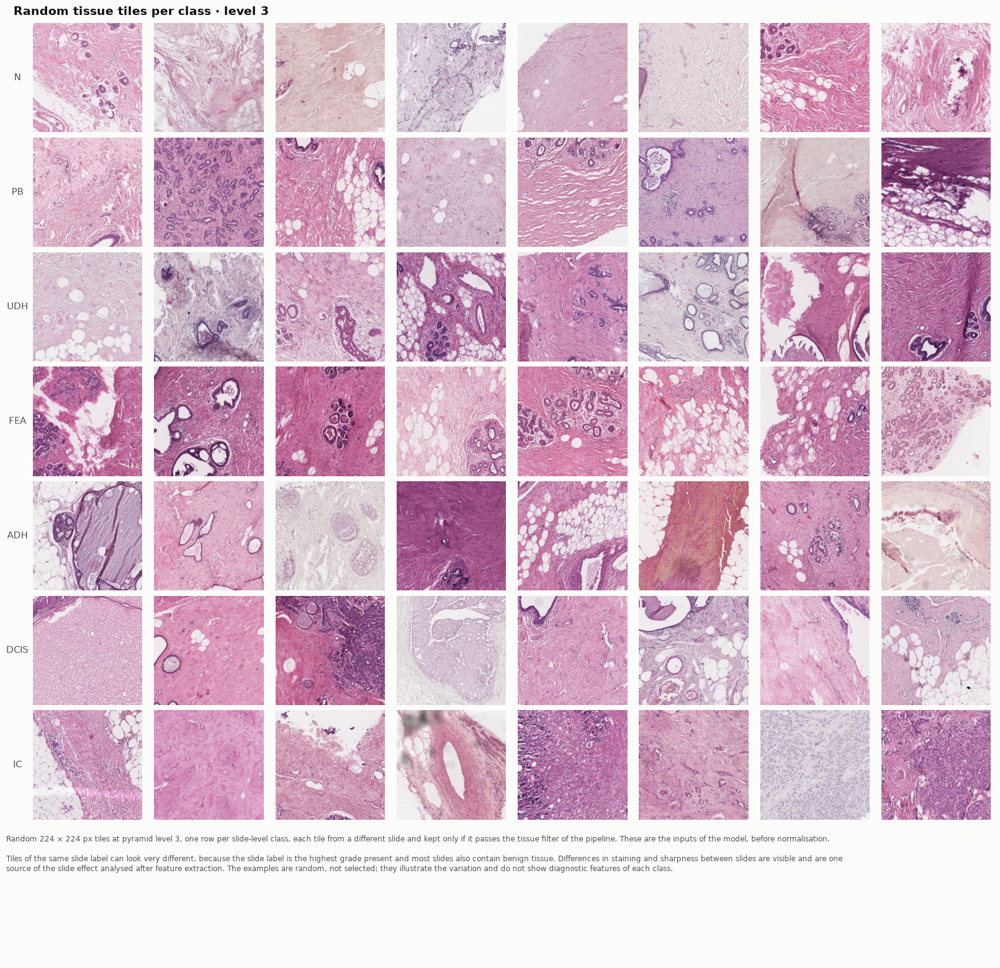

In [13]:
# STEP 1: Eight random tissue tiles per class (different slides) at TILE_EXAMPLE_LEVEL
examples = plot_tile_examples(table, level=TILE_EXAMPLE_LEVEL, n_per_class=8, tile_size=TILE_SIZE, seed=SEED)

## 6. Summary and export

### 6.1 Main facts
The main facts about the data set in one table, computed from the results above, for use in the methods section of the thesis.

In [14]:
# STEP 1: Collect the main facts
summary = build_summary(table, audit, weighting['weights'])
summary

,item,value
0,slides / patients,547 / 189
1,slides per set (Training / Validation / Testing),395 / 65 / 87
2,slides per class,"N 44, PB 147, UDH 74, FEA 41, ADH 48, DCIS 61,..."
3,imbalance ratio in Training (largest / smalles...,5.0
4,"class x set association (Cramer's V, permutati...","0.15, p = 0.47"
5,patients with slides in several sets,67
6,patients with slides of several classes,78 of 189
7,scanner / magnification,SS7212 / 40x
8,MPP values (um per pixel),"0.2519 (481), 0.2524 (66)"
9,scan years,"2019 (228), 2020 (253), 2021 (66)"


### 6.2 Export
Writes the tidy slide table (label, patient, official set, technical properties) and the class weights computed on the Training set. Later notebooks read these files instead of recomputing them, so that the split and the weights are the same everywhere.

In [15]:
# STEP 1: Write the tables (the local file path of every slide is left out)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
table.drop(columns=['path']).to_csv(OUTPUT_DIR / 'slides.csv', index=False)

# STEP 2: Class weights per method, with the Training counts they were computed from
weights = pd.DataFrame({'class': BRACS_CLASSES, 'n_train': weighting['counts'], **weighting['weights']})
weights.to_csv(OUTPUT_DIR / 'class_weights.csv', index=False)
print(f'Wrote {OUTPUT_DIR / "slides.csv"} ({len(table)} rows) and {OUTPUT_DIR / "class_weights.csv"}')
weights

Wrote outputs/00_data_overview/slides.csv (547 rows) and outputs/00_data_overview/class_weights.csv


,class,n_train,inverse,sqrt,effective
0,N,27,2.089947,1.515840,2.059403
1,PB,120,0.470238,0.719026,0.485156
2,UDH,56,1.007653,1.052546,1.007335
3,FEA,24,2.351191,1.607791,2.313369
4,ADH,28,2.015306,1.488525,1.986842
5,DCIS,40,1.410714,1.245389,1.399116
6,IC,100,0.564286,0.787654,0.576497
